# Clasificación de imágenes de MRI cerebral con redes neuronales convolucionales
## Miniproyecto 1 - Técnicas de Deep Learning (MAIA)

El objetivo es clasificar cortes 2D de resonancia magnética (MRI) cerebral en cuatro categorías: **glioma**, **meningioma**, **tumor pituitario (hipófisis)** y **tejido sano**. Se usan las 7023 imágenes del dataset público *Brain Tumor MRI Dataset* (Kaggle), guardadas en la carpeta `imagenes/` con una subcarpeta por clase.

Se comparan dos modelos:

1. **CNN propia**: cuatro bloques de convolución + max pooling, en la línea del laboratorio de CNN del curso.
2. **ResNet18 con fine-tuning**: red preentrenada en ImageNet a la que se le cambia la última capa para 4 clases.

Cada modelo se entrena con 3 semillas distintas para reportar promedio y desviación estándar de las métricas.

**Contenido del notebook**
1. Preparación de los datos (carga, eliminación de duplicados, división train/val/test)
2. Arquitecturas
3. Entrenamiento y evaluación
4. Resultados cuantitativos
5. Resultados cualitativos

In [1]:
# Celda con la importación de librerías

import copy                      # Copiar los pesos del mejor modelo
import hashlib                   # Huella MD5 de cada archivo para detectar duplicados
import json                      # Guardar los resultados en disco
import time                      # Medir el tiempo de entrenamiento
from pathlib import Path         # Manejo de rutas

import numpy as np               # Librería para trabajar con datos matriciales
import matplotlib.pyplot as plt  # Librería para gráficas y visualización
from PIL import Image            # Lectura de imágenes

import torch                     # Importar PyTorch
import torch.nn as nn            # Módulo de redes neuronales de PyTorch
import torch.optim as optim      # Optimizadores de PyTorch
from torchvision.models import resnet18, ResNet18_Weights  # Red preentrenada

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, recall_score,
                             confusion_matrix, classification_report)

# Inicialización de semillas
torch.manual_seed(42)
np.random.seed(42)

# Dispositivo de cómputo (usa GPU si está disponible)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Dispositivo:', device)

Dispositivo: cpu


In [2]:
# Parámetros generales del experimento

DATA_DIR = Path('imagenes')                                     # Carpeta con una subcarpeta por clase
CLASS_DIRS = ['glioma', 'healthy', 'meningioma', 'pituitary']    # El índice en la lista es la etiqueta
CLASS_NAMES = ['Glioma', 'Sano', 'Meningioma', 'Pituitario']     # Nombres usados en las figuras
IMG_SIZE = 128                                                   # Las imágenes se redimensionan a 128x128

SPLIT_SEED = 42          # Semilla de la división train/val/test (fija para todos los experimentos)
SEEDS = [0, 1, 2]        # Semillas de entrenamiento (inicialización de pesos y orden de los lotes)
BATCH_SIZE = 32

FIG_DIR = Path('figuras')        # Figuras usadas en el informe
RES_DIR = Path('resultados')     # Métricas guardadas en disco
FIG_DIR.mkdir(exist_ok=True)
RES_DIR.mkdir(exist_ok=True)

# Las figuras del informe usan la fuente del documento (Times New Roman) y se dibujan
# al doble del ancho de una columna del informe, por eso el tamaño de letra es 14
plt.rcParams.update({'font.family': 'serif', 'font.serif': ['Times New Roman', 'DejaVu Serif'],
                     'font.size': 14})

## 1. Preparación de los datos

El pipeline de carga hace cuatro cosas:

1. **Elimina duplicados exactos.** El dataset trae archivos repetidos byte a byte (sobre todo en la clase sana). Si no se quitan, una misma imagen puede quedar en entrenamiento y en prueba, y la exactitud de prueba sale inflada. Se calcula la huella MD5 de cada archivo y se conserva solo la primera aparición.
2. **Convierte a escala de grises.** Las MRI son de un solo canal aunque los JPEG vengan en RGB.
3. **Redimensiona a 128x128.** Las imágenes originales tienen tamaños distintos (la mayoría 512x512). 128x128 conserva la forma del tumor y permite entrenar en CPU.
4. **Normaliza** los píxeles al rango [0, 1].

In [3]:
def load_data(data_dir, class_dirs, img_size):
    '''
    Esta función carga las imágenes de MRI como tensores de PyTorch, eliminando los
    archivos duplicados.
    Parámetros de entrada:
    data_dir = Carpeta con una subcarpeta por clase
    class_dirs = Lista con los nombres de las subcarpetas (el índice es la etiqueta)
    img_size = Lado de la imagen redimensionada
    Parámetros de salida:
    X = Imágenes, tensor de forma (N, 1, img_size, img_size) con valores en [0, 1]
    y = Etiquetas (índices de clase 0-3)
    '''
    images, labels = [], []
    seen = set()                  # Huellas MD5 de los archivos ya cargados
    n_files = np.zeros(len(class_dirs), dtype=int)
    n_dups = np.zeros(len(class_dirs), dtype=int)

    for label, class_dir in enumerate(class_dirs):
        for path in sorted((data_dir / class_dir).glob('*.jpg')):
            n_files[label] += 1
            fingerprint = hashlib.md5(path.read_bytes()).hexdigest()
            if fingerprint in seen:          # Archivo idéntico a uno ya cargado
                n_dups[label] += 1
                continue
            seen.add(fingerprint)

            # Escala de grises, redimensionamiento y normalización
            img = Image.open(path).convert('L').resize((img_size, img_size), Image.BILINEAR)
            images.append(np.asarray(img, dtype=np.float32) / 255.0)
            labels.append(label)

    X = torch.tensor(np.stack(images)).unsqueeze(1)   # Se agrega la dimensión del canal (N, C, H, W)
    y = torch.tensor(labels)

    print(f'Archivos por clase:            {n_files}  (total {n_files.sum()})')
    print(f'Duplicados eliminados:         {n_dups}  (total {n_dups.sum()})')
    print(f'Imágenes únicas por clase:     {np.bincount(y.numpy())}  (total {len(y)})')
    print(f'Tamaño del tensor de imágenes: {tuple(X.shape)}')
    return X, y

In [4]:
X, y = load_data(DATA_DIR, CLASS_DIRS, IMG_SIZE)

Archivos por clase:            [1621 2000 1645 1757]  (total 7023)
Duplicados eliminados:         [  1 294 114  17]  (total 426)
Imágenes únicas por clase:     [1620 1706 1531 1740]  (total 6597)
Tamaño del tensor de imágenes: (6597, 1, 128, 128)


**Tamaño original de las imágenes por clase.** El dataset junta imágenes de varias fuentes. Revisar el tamaño original por clase permite ver si alguna clase proviene de una fuente distinta, lo que el modelo podría aprovechar como atajo en lugar de aprender la patología.

In [5]:
def original_sizes(data_dir, class_dirs):
    '''
    Imprime, para cada clase, cuántos tamaños de imagen distintos hay y qué
    porcentaje de las imágenes mide 512x512 píxeles.
    '''
    for class_dir in class_dirs:
        sizes = [Image.open(p).size for p in sorted((data_dir / class_dir).glob('*.jpg'))]
        pct_512 = 100 * np.mean([s == (512, 512) for s in sizes])
        print(f'{class_dir:<11} tamaños distintos: {len(set(sizes)):>3} | imágenes de 512x512: {pct_512:5.1f} %')


original_sizes(DATA_DIR, CLASS_DIRS)

glioma      tamaños distintos:   1 | imágenes de 512x512: 100.0 %


healthy     tamaños distintos: 254 | imágenes de 512x512:   1.0 %


meningioma  tamaños distintos: 129 | imágenes de 512x512:  84.3 %


pituitary   tamaños distintos:  16 | imágenes de 512x512:  97.6 %


**División de los datos.** Se usa una división estratificada 70 % / 15 % / 15 % (entrenamiento / validación / prueba), de modo que cada conjunto mantiene la proporción de clases. El conjunto de validación se usa para escoger la mejor época de cada entrenamiento; el de prueba solo se usa al final para reportar métricas.

In [6]:
def split_data(X, y, seed):
    '''
    Divide los datos en entrenamiento (70 %), validación (15 %) y prueba (15 %)
    de forma estratificada.
    Parámetros de entrada:
    X, y = imágenes y etiquetas
    seed = semilla de la división
    Parámetros de salida:
    (X_train, y_train), (X_val, y_val), (X_test, y_test)
    '''
    idx = np.arange(len(y))
    idx_train, idx_tmp = train_test_split(idx, test_size=0.30, stratify=y.numpy(), random_state=seed)
    idx_val, idx_test = train_test_split(idx_tmp, test_size=0.50, stratify=y[idx_tmp].numpy(),
                                         random_state=seed)
    for name, ids in [('Entrenamiento', idx_train), ('Validación', idx_val), ('Prueba', idx_test)]:
        print(f'{name:<14} {len(ids):>5} imágenes, por clase {np.bincount(y[ids].numpy())}')
    return (X[idx_train], y[idx_train]), (X[idx_val], y[idx_val]), (X[idx_test], y[idx_test])


(X_train, y_train), (X_val, y_val), (X_test, y_test) = split_data(X, y, SPLIT_SEED)

Entrenamiento   4617 imágenes, por clase [1134 1194 1071 1218]
Validación       990 imágenes, por clase [243 256 230 261]
Prueba           990 imágenes, por clase [243 256 230 261]


**¿Cuánto afectan los duplicados?** Para justificar su eliminación se repite la misma división 70/15/15 sobre los 7023 archivos originales (sin quitar duplicados) y se cuenta cuántas imágenes de prueba tienen una copia idéntica en entrenamiento.

In [7]:
def count_leakage_without_dedup(data_dir, class_dirs, seed):
    '''
    Divide los archivos originales (con duplicados) igual que split_data y cuenta
    cuántas imágenes de prueba tienen una copia idéntica en entrenamiento.
    '''
    fingerprints, labels = [], []
    for label, class_dir in enumerate(class_dirs):
        for path in sorted((data_dir / class_dir).glob('*.jpg')):
            fingerprints.append(hashlib.md5(path.read_bytes()).hexdigest())
            labels.append(label)
    fingerprints, labels = np.array(fingerprints), np.array(labels)

    idx = np.arange(len(labels))
    idx_train, idx_tmp = train_test_split(idx, test_size=0.30, stratify=labels, random_state=seed)
    _, idx_test = train_test_split(idx_tmp, test_size=0.50, stratify=labels[idx_tmp], random_state=seed)

    train_fingerprints = set(fingerprints[idx_train])
    leaked = np.array([fingerprints[i] in train_fingerprints for i in idx_test])
    print(f'Imágenes de prueba con copia en entrenamiento: {leaked.sum()} de {len(idx_test)} '
          f'({100 * leaked.mean():.1f} %)')
    print(f'Por clase: {[int(leaked[labels[idx_test] == c].sum()) for c in range(len(class_dirs))]}')


count_leakage_without_dedup(DATA_DIR, CLASS_DIRS, SPLIT_SEED)

Imágenes de prueba con copia en entrenamiento: 75 de 1054 (7.1 %)
Por clase: [0, 49, 24, 2]


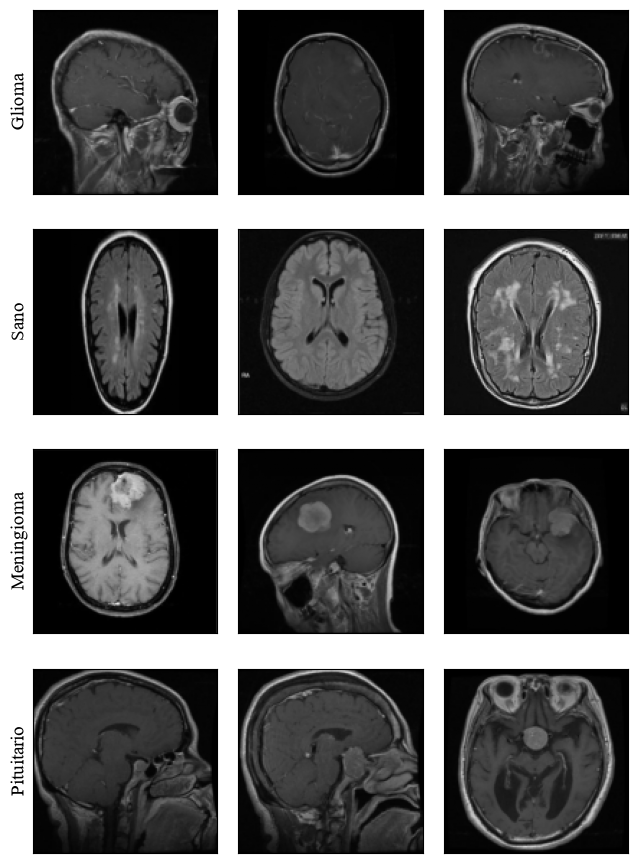

In [8]:
def visualize_instances(X_data, y_data, n_per_class=3):
    '''
    Esta función visualiza algunas imágenes de cada categoría.
    Parámetros de entrada:
    X_data = Instancias, tensor de forma (N, 1, H, W)
    y_data = Etiquetas
    n_per_class = número de imágenes por clase
    Parámetros de salida:
    Gráfica con una fila por clase.
    '''
    fig, ax = plt.subplots(len(CLASS_NAMES), n_per_class, figsize=(2.2 * n_per_class, 9))
    for c, name in enumerate(CLASS_NAMES):
        imgs = X_data[y_data == c]
        for j in range(n_per_class):
            ax[c, j].imshow(imgs[j, 0], cmap='gray', vmin=0, vmax=1)
            ax[c, j].set_xticks([])
            ax[c, j].set_yticks([])
        ax[c, 0].set_ylabel(name)
    plt.tight_layout()
    plt.show()


visualize_instances(X_train, y_train)

## 2. Arquitecturas

**CNN propia.** Sigue la estructura del laboratorio de CNN (convolución + ReLU + max pooling, luego capas densas con Dropout), pero con cuatro bloques porque las imágenes son más grandes (128x128 frente a 28x28). Cada bloque reduce la resolución a la mitad y duplica el número de filtros. Se agrega `BatchNorm2d` después de cada convolución para estabilizar el entrenamiento.

**ResNet18 con fine-tuning.** Red residual de 18 capas preentrenada en ImageNet [He et al., 2016]. Se reemplaza la capa final (1000 clases) por una de 4 y se ajustan todos los pesos con una tasa de aprendizaje baja. Como ResNet espera imágenes RGB, la imagen en gris se repite en los 3 canales y se normaliza con la media y desviación de ImageNet.

In [9]:
def load_cnn():
    '''
    Esta función construye la CNN propia para clasificar las MRI en 4 clases.
    Salida:
    model = modelo neuronal convolucional en PyTorch (nn.Module)
    '''
    # Nota: no se agrega softmax en la salida porque nn.CrossEntropyLoss la aplica internamente
    model = nn.Sequential(
        # Bloque 1: 16 filtros de 3x3 (128x128 -> 64x64)
        nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, padding=1),
        nn.BatchNorm2d(16),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2),
        # Bloque 2: 32 filtros de 3x3 (64x64 -> 32x32)
        nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1),
        nn.BatchNorm2d(32),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2),
        # Bloque 3: 64 filtros de 3x3 (32x32 -> 16x16)
        nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1),
        nn.BatchNorm2d(64),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2),
        # Bloque 4: 128 filtros de 3x3 (16x16 -> 8x8)
        nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, padding=1),
        nn.BatchNorm2d(128),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2),
        # Capa de aplanamiento
        nn.Flatten(),
        # Capa densa oculta con Dropout para reducir el sobreajuste
        nn.Linear(128 * 8 * 8, 128),
        nn.ReLU(),
        nn.Dropout(0.5),
        # Capa de salida
        nn.Linear(128, 4)
    )
    return model


class ResNetMRI(nn.Module):
    '''
    ResNet18 preentrenada en ImageNet con la última capa cambiada a 4 clases.
    Recibe imágenes en gris (N, 1, H, W) con valores en [0, 1].
    '''
    def __init__(self):
        super().__init__()
        self.net = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
        self.net.fc = nn.Linear(self.net.fc.in_features, 4)   # 512 -> 4 clases
        # Media y desviación de ImageNet para normalizar la entrada
        self.register_buffer('mean', torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer('std', torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, x):
        x = x.repeat(1, 3, 1, 1)              # Gris -> 3 canales
        x = (x - self.mean) / self.std         # Normalización de ImageNet
        return self.net(x)


def count_parameters(model):
    '''Número de parámetros entrenables del modelo.'''
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


print(f'Parámetros CNN propia: {count_parameters(load_cnn()):,}')
print(f'Parámetros ResNet18:   {count_parameters(ResNetMRI()):,}')

Parámetros CNN propia: 1,146,852
Parámetros ResNet18:   11,178,564


## 3. Entrenamiento y evaluación

Las funciones de entrenamiento y evaluación son las del laboratorio, con tres cambios:

- Se evalúa en **validación** (no en prueba) al final de cada época.
- Se guardan los pesos de la época con **mayor exactitud de validación** y se restauran al terminar (*early stopping* sin detener el entrenamiento).
- **Aumento de datos:** en cada lote, la mitad de las imágenes (al azar) se voltea horizontalmente. El cerebro es aproximadamente simétrico y el tumor puede estar en cualquiera de los dos hemisferios, así que la etiqueta no cambia.

In [10]:
def evaluate_model(model, X, y, batch_size=128, criterion=None):
    '''
    Evalúa `model` sobre (X, y) y calcula la pérdida y exactitud promedio.
    Parámetros de entrada:
    model = modelo de PyTorch (nn.Module)
    X, y = datos y etiquetas sobre los que evaluar
    batch_size = tamaño de lote usado para recorrer los datos
    criterion = función de pérdida (por defecto nn.CrossEntropyLoss)
    Salida:
    loss = pérdida promedio
    accuracy = exactitud promedio
    '''
    if criterion is None:
        criterion = nn.CrossEntropyLoss()

    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for i in range(0, len(X), batch_size):
            X_batch = X[i:i + batch_size].to(device)
            y_batch = y[i:i + batch_size].to(device)

            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)

            total_loss += loss.item() * len(X_batch)
            correct += (outputs.argmax(dim=1) == y_batch).sum().item()
            total += len(X_batch)

    return total_loss / total, correct / total


def train_model(model, X_train, y_train, X_val, y_val, optimizer,
                epochs=10, batch_size=32, criterion=None):
    '''
    Entrena `model` durante `epochs` épocas usando mini-lotes de tamaño `batch_size`,
    evaluando en cada época sobre (X_val, y_val). Al final restaura los pesos de la
    época con mayor exactitud de validación.
    Parámetros de entrada:
    model = modelo de PyTorch (nn.Module)
    X_train, y_train = datos y etiquetas de entrenamiento
    X_val, y_val = datos y etiquetas de validación
    optimizer = optimizador de torch.optim ya asociado a los parámetros de `model`
    epochs = número de épocas de entrenamiento
    batch_size = tamaño de mini-lote
    criterion = función de pérdida (por defecto nn.CrossEntropyLoss)
    Salida:
    history = diccionario con las llaves 'accuracy', 'val_accuracy', 'loss', 'val_loss'
              y 'best_epoch'
    '''
    if criterion is None:
        criterion = nn.CrossEntropyLoss()

    model.to(device)
    n_train = len(X_train)
    history = {'accuracy': [], 'val_accuracy': [], 'loss': [], 'val_loss': []}
    best_val_acc, best_state = -1.0, None

    for epoch in range(epochs):
        model.train()
        perm = torch.randperm(n_train)
        running_loss, correct, total = 0.0, 0, 0

        for i in range(0, n_train, batch_size):
            idx = perm[i:i + batch_size]
            X_batch = X_train[idx]          # Copia del lote (no modifica X_train)
            y_batch = y_train[idx]

            # Aumento de datos: volteo horizontal de la mitad de las imágenes del lote
            flip = torch.rand(len(X_batch)) < 0.5
            X_batch[flip] = X_batch[flip].flip(dims=[3])

            X_batch, y_batch = X_batch.to(device), y_batch.to(device)

            optimizer.zero_grad()
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * len(X_batch)
            correct += (outputs.argmax(dim=1) == y_batch).sum().item()
            total += len(X_batch)

        train_loss, train_acc = running_loss / total, correct / total
        val_loss, val_acc = evaluate_model(model, X_val, y_val, criterion=criterion)

        history['accuracy'].append(train_acc)
        history['val_accuracy'].append(val_acc)
        history['loss'].append(train_loss)
        history['val_loss'].append(val_loss)

        # Se guardan los pesos de la mejor época en validación
        if val_acc > best_val_acc:
            best_val_acc, best_state = val_acc, copy.deepcopy(model.state_dict())
            history['best_epoch'] = epoch + 1

        print(f"Epoch {epoch + 1}/{epochs} - loss: {train_loss:.4f} - accuracy: {train_acc:.4f} "
              f"- val_loss: {val_loss:.4f} - val_accuracy: {val_acc:.4f}")

    model.load_state_dict(best_state)
    print(f"Mejor época: {history['best_epoch']} (val_accuracy = {best_val_acc:.4f})")
    return history


def predict(model, X, batch_size=128):
    '''
    Devuelve la clase predicha para cada imagen de X.
    '''
    model.eval()
    preds = []
    with torch.no_grad():
        for i in range(0, len(X), batch_size):
            preds.append(model(X[i:i + batch_size].to(device)).argmax(dim=1).cpu())
    return torch.cat(preds).numpy()

**Configuración de los experimentos.** Ambos modelos usan entropía cruzada como función de pérdida, el optimizador Adam y lotes de 32 imágenes. La tasa de aprendizaje de ResNet18 es 10 veces menor para no destruir los filtros preentrenados, y necesita menos épocas porque parte de pesos que ya reconocen bordes y texturas.

Cada configuración se entrena con 3 semillas. La división de datos es la misma en todos los casos; la semilla solo cambia la inicialización de los pesos, el orden de los lotes y los volteos.

In [11]:
EXPERIMENTS = {
    'CNN propia': {'build': load_cnn,  'lr': 1e-3, 'epochs': 15},
    'ResNet18':   {'build': ResNetMRI, 'lr': 1e-4, 'epochs': 6},
}

runs = []                                  # Una entrada por (modelo, semilla)
models_seed0 = {}                          # Modelos entrenados con la primera semilla

for name, cfg in EXPERIMENTS.items():
    for seed in SEEDS:
        print(f'\n===== {name} | semilla {seed} =====')
        torch.manual_seed(seed)
        np.random.seed(seed)

        model = cfg['build']()
        optimizer = optim.Adam(model.parameters(), lr=cfg['lr'])

        start = time.time()
        history = train_model(model, X_train, y_train, X_val, y_val, optimizer=optimizer,
                              epochs=cfg['epochs'], batch_size=BATCH_SIZE)
        minutes = (time.time() - start) / 60

        y_pred = predict(model, X_test)
        runs.append({
            'model': name,
            'seed': seed,
            'history': history,
            'minutes': minutes,
            'params': count_parameters(model),
            'y_pred': y_pred.tolist(),
            'accuracy': accuracy_score(y_test, y_pred),
            'f1_macro': f1_score(y_test, y_pred, average='macro'),
            'recall_per_class': recall_score(y_test, y_pred, average=None).tolist(),
        })
        print(f"Prueba: accuracy = {runs[-1]['accuracy']:.4f} | F1 macro = {runs[-1]['f1_macro']:.4f} "
              f"| tiempo = {minutes:.1f} min")
        if seed == SEEDS[0]:
            models_seed0[name] = model

# Se guardan los resultados para poder rastrear los números del informe
with open(RES_DIR / 'resultados.json', 'w', encoding='utf-8') as f:
    json.dump({'y_test': y_test.tolist(), 'class_names': CLASS_NAMES, 'runs': runs}, f, indent=1)


===== CNN propia | semilla 0 =====


Epoch 1/15 - loss: 0.9157 - accuracy: 0.6459 - val_loss: 0.4878 - val_accuracy: 0.8162


Epoch 2/15 - loss: 0.5780 - accuracy: 0.7598 - val_loss: 0.4808 - val_accuracy: 0.7909


Epoch 3/15 - loss: 0.5164 - accuracy: 0.7888 - val_loss: 0.4283 - val_accuracy: 0.8313


Epoch 4/15 - loss: 0.4574 - accuracy: 0.8152 - val_loss: 0.3914 - val_accuracy: 0.8475


...

Epoch 3/6 - loss: 0.0622 - accuracy: 0.9799 - val_loss: 0.0804 - val_accuracy: 0.9747


Epoch 4/6 - loss: 0.0456 - accuracy: 0.9838 - val_loss: 0.0389 - val_accuracy: 0.9848


Epoch 5/6 - loss: 0.0339 - accuracy: 0.9894 - val_loss: 0.0430 - val_accuracy: 0.9838


Epoch 6/6 - loss: 0.0222 - accuracy: 0.9933 - val_loss: 0.0482 - val_accuracy: 0.9828
Mejor época: 4 (val_accuracy = 0.9848)


Prueba: accuracy = 0.9798 | F1 macro = 0.9793 | tiempo = 9.4 min


## 4. Resultados cuantitativos

**Métricas.** Se reporta la exactitud (*accuracy*) global y el **F1 macro**, que promedia el F1 de las cuatro clases con el mismo peso y por eso no se deja dominar por la clase más grande (sana). También se reporta la **sensibilidad (recall) por clase**: en un contexto clínico el error más costoso es no detectar un tumor, y el recall mide justamente qué fracción de cada clase se detecta. Todas las métricas son promedio ± desviación estándar sobre las 3 semillas, medidas en el conjunto de prueba.

In [12]:
def summarize(values):
    '''Texto "promedio ± desviación estándar" en porcentaje.'''
    values = 100 * np.array(values)
    return f'{values.mean():.1f} ± {values.std(ddof=1):.1f}'


header = ['Modelo', 'Accuracy', 'F1 macro'] + [f'Recall {c}' for c in CLASS_NAMES] + ['Épocas', 'Mejor época', 'Min/entren.', 'Parámetros']
print(' | '.join(header))
for name in EXPERIMENTS:
    model_runs = [r for r in runs if r['model'] == name]
    row = [name,
           summarize([r['accuracy'] for r in model_runs]),
           summarize([r['f1_macro'] for r in model_runs])]
    row += [summarize([r['recall_per_class'][c] for r in model_runs]) for c in range(len(CLASS_NAMES))]
    row += [str(EXPERIMENTS[name]['epochs']),
            str([r['history']['best_epoch'] for r in model_runs]),
            f"{np.mean([r['minutes'] for r in model_runs]):.1f}",
            f"{model_runs[0]['params']:,}"]
    print(' | '.join(row))

Modelo | Accuracy | F1 macro | Recall Glioma | Recall Sano | Recall Meningioma | Recall Pituitario | Épocas | Mejor época | Min/entren. | Parámetros
CNN propia | 93.9 ± 0.3 | 93.7 ± 0.3 | 87.2 ± 4.7 | 96.7 ± 0.2 | 92.8 ± 3.3 | 98.3 ± 0.6 | 15 | [12, 15, 15] | 12.8 | 1,146,852
ResNet18 | 98.2 ± 0.4 | 98.2 ± 0.4 | 97.9 ± 1.8 | 98.4 ± 0.4 | 97.2 ± 1.8 | 99.1 ± 0.2 | 6 | [4, 4, 4] | 9.7 | 11,178,564


In [13]:
# Detalle por semilla
for r in runs:
    print(f"{r['model']:<11} semilla {r['seed']}: accuracy = {100 * r['accuracy']:.2f} %, "
          f"F1 macro = {100 * r['f1_macro']:.2f} %, mejor época = {r['history']['best_epoch']}")

CNN propia  semilla 0: accuracy = 94.04 %, F1 macro = 93.87 %, mejor época = 12
CNN propia  semilla 1: accuracy = 93.54 %, F1 macro = 93.36 %, mejor época = 15
CNN propia  semilla 2: accuracy = 94.14 %, F1 macro = 94.01 %, mejor época = 15
ResNet18    semilla 0: accuracy = 98.69 %, F1 macro = 98.66 %, mejor época = 4
ResNet18    semilla 1: accuracy = 97.98 %, F1 macro = 97.93 %, mejor época = 4
ResNet18    semilla 2: accuracy = 97.98 %, F1 macro = 97.93 %, mejor época = 4


In [14]:
# Reporte completo por clase (precision, recall, F1) para la primera semilla de cada modelo
for name in EXPERIMENTS:
    r = next(r for r in runs if r['model'] == name and r['seed'] == SEEDS[0])
    print(f'===== {name} (semilla {SEEDS[0]}) =====')
    print(classification_report(y_test, r['y_pred'], target_names=CLASS_NAMES, digits=3))

===== CNN propia (semilla 0) =====
              precision    recall  f1-score   support

      Glioma      0.969     0.893     0.929       243
        Sano      0.973     0.969     0.971       256
  Meningioma      0.860     0.904     0.881       230
  Pituitario      0.959     0.989     0.974       261

    accuracy                          0.940       990
   macro avg      0.940     0.939     0.939       990
weighted avg      0.942     0.940     0.941       990

===== ResNet18 (semilla 0) =====
              precision    recall  f1-score   support

      Glioma      0.996     0.988     0.992       243
        Sano      0.992     0.988     0.990       256
  Meningioma      0.966     0.983     0.974       230
  Pituitario      0.992     0.989     0.990       261

    accuracy                          0.987       990
   macro avg      0.987     0.987     0.987       990
weighted avg      0.987     0.987     0.987       990



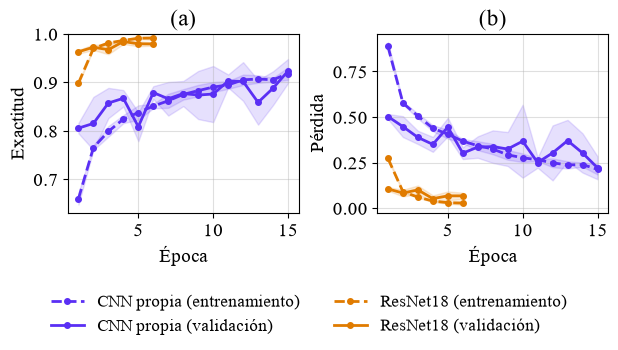

In [15]:
def visualization_history(runs, experiments):
    '''
    Grafica las curvas de exactitud y pérdida por época de cada modelo
    (promedio sobre las semillas; la banda sombreada es ± 1 desviación estándar).
    Parámetros:
    runs = lista de resultados por (modelo, semilla)
    experiments = diccionario con la configuración de cada modelo
    Salida:
    Gráfica con la exactitud (izquierda) y la pérdida (derecha).
    '''
    colors = {'CNN propia': '#5a2ff4', 'ResNet18': '#e07b00'}
    fig, axes = plt.subplots(1, 2, figsize=(6.4, 3.6))

    for name in experiments:
        hists = [r['history'] for r in runs if r['model'] == name]
        epochs = np.arange(1, len(hists[0]['accuracy']) + 1)
        for ax, key in [(axes[0], 'accuracy'), (axes[1], 'loss')]:
            for split, style in [('', '--'), ('val_', '-')]:
                values = np.array([h[split + key] for h in hists])
                mean, std = values.mean(axis=0), values.std(axis=0, ddof=1)
                label = f"{name} ({'validación' if split else 'entrenamiento'})"
                ax.plot(epochs, mean, style, color=colors[name], marker='o', ms=4, lw=2, label=label)
                ax.fill_between(epochs, mean - std, mean + std, color=colors[name], alpha=0.15)

    axes[0].set_ylabel('Exactitud')
    axes[0].set_ylim(top=1.0)
    axes[1].set_ylabel('Pérdida')
    for ax, letter in zip(axes, ['(a)', '(b)']):
        ax.set_xlabel('Época')
        ax.set_title(letter)
        ax.grid(alpha=0.4)
    # Una sola leyenda para las dos gráficas, debajo de ellas
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', ncol=2, fontsize=12, frameon=False)
    plt.tight_layout(rect=(0, 0.17, 1, 1))
    fig.savefig(FIG_DIR / 'curvas_entrenamiento.png', dpi=300, bbox_inches='tight')
    plt.show()


visualization_history(runs, EXPERIMENTS)

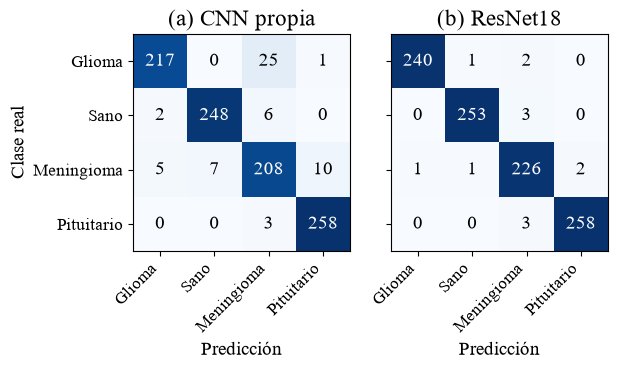

In [16]:
def plot_confusion_matrices(runs, y_test, seed):
    '''
    Matrices de confusión en el conjunto de prueba, una por modelo, para la semilla dada.
    Cada celda muestra el número de imágenes; el color indica el porcentaje de la fila
    (respecto a la clase real).
    '''
    names = list(EXPERIMENTS)
    fig, axes = plt.subplots(1, len(names), figsize=(6.4, 3.7))
    for ax, name, letter in zip(axes, names, ['(a)', '(b)']):
        r = next(r for r in runs if r['model'] == name and r['seed'] == seed)
        cm = confusion_matrix(y_test, r['y_pred'])
        cm_pct = 100 * cm / cm.sum(axis=1, keepdims=True)
        ax.imshow(cm_pct, cmap='Blues', vmin=0, vmax=100)
        for i in range(len(CLASS_NAMES)):
            for j in range(len(CLASS_NAMES)):
                color = 'white' if cm_pct[i, j] > 60 else 'black'
                ax.text(j, i, str(cm[i, j]), ha='center', va='center', fontsize=14, color=color)
        ax.set_xticks(range(len(CLASS_NAMES)))
        ax.set_xticklabels(CLASS_NAMES, rotation=45, ha='right', fontsize=12)
        ax.set_yticks(range(len(CLASS_NAMES)))
        ax.set_yticklabels(CLASS_NAMES if ax is axes[0] else [], fontsize=12)
        ax.set_xlabel('Predicción')
        ax.set_title(f'{letter} {name}')
    axes[0].set_ylabel('Clase real')
    plt.tight_layout()
    fig.savefig(FIG_DIR / 'matrices_confusion.png', dpi=300, bbox_inches='tight')
    plt.show()


plot_confusion_matrices(runs, y_test, SEEDS[0])

## 5. Resultados cualitativos

Se muestran imágenes de prueba con la etiqueta real y la predicción de cada modelo (primera semilla). La fila superior tiene un acierto de ambos modelos por clase; la fila inferior tiene casos donde al menos un modelo se equivoca. El texto en verde es un acierto y en rojo un error.

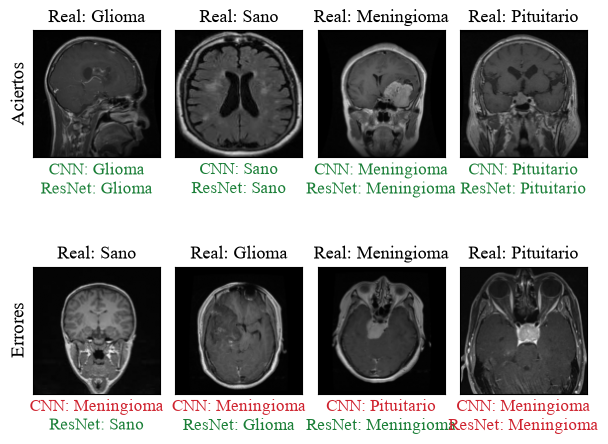

In [17]:
def plot_predictions(X_test, y_test, runs, seed, n_cols=4):
    '''
    Muestra ejemplos de prueba con la etiqueta real y la predicción de cada modelo.
    Fila 1: un acierto de ambos modelos por clase.
    Fila 2: casos en que al menos un modelo falla (de clases reales distintas si es posible).
    '''
    names = list(EXPERIMENTS)
    short = {'CNN propia': 'CNN', 'ResNet18': 'ResNet'}
    preds = {n: np.array(next(r for r in runs if r['model'] == n and r['seed'] == seed)['y_pred'])
             for n in names}
    y_true = y_test.numpy()
    all_ok = np.all([preds[n] == y_true for n in names], axis=0)

    rng = np.random.default_rng(0)
    order = rng.permutation(len(y_true))      # Orden aleatorio fijo para escoger los ejemplos

    # Fila 1: primer acierto de cada clase
    row_ok = []
    for c in range(len(CLASS_NAMES)):
        hits = [i for i in order if all_ok[i] and y_true[i] == c]
        if hits:
            row_ok.append(hits[0])
    # Fila 2: errores, priorizando clases reales distintas
    errors = [i for i in order if not all_ok[i]]
    row_err = []
    for i in errors:
        if y_true[i] not in [y_true[j] for j in row_err]:
            row_err.append(i)
    row_err += [i for i in errors if i not in row_err]
    row_err = row_err[:n_cols]

    fig, axes = plt.subplots(2, n_cols, figsize=(1.6 * n_cols, 5.0))
    for row, idxs in enumerate([row_ok, row_err]):
        for col in range(n_cols):
            ax = axes[row, col]
            ax.set_xticks([])
            ax.set_yticks([])
            if col >= len(idxs):
                ax.axis('off')
                continue
            i = idxs[col]
            ax.imshow(X_test[i, 0], cmap='gray', vmin=0, vmax=1)
            ax.set_title(f'Real: {CLASS_NAMES[y_true[i]]}', fontsize=13)
            for k, n in enumerate(names):
                ok = preds[n][i] == y_true[i]
                ax.text(0.5, -0.04 - 0.15 * k, f'{short[n]}: {CLASS_NAMES[preds[n][i]]}',
                        transform=ax.transAxes, ha='center', va='top', fontsize=12,
                        color='#1a7f37' if ok else '#cf222e')
    axes[0, 0].set_ylabel('Aciertos')
    axes[1, 0].set_ylabel('Errores')
    plt.tight_layout(h_pad=1.4, w_pad=0.2)
    plt.subplots_adjust(wspace=0.12)
    fig.savefig(FIG_DIR / 'ejemplos_predicciones.png', dpi=300, bbox_inches='tight')
    plt.show()


plot_predictions(X_test, y_test, runs, SEEDS[0])